In [5]:
import json
import os
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [3]:
BASE_PATH = "/home/jupyter/advanced/cv"
OUTPUT_PATH = "/home/jupyter/yolo"

with open(BASE_PATH + "/annotations.json") as f:
    data = json.load(f)

print(data.keys())



dict_keys(['info', 'images', 'annotations', 'licenses', 'categories'])


In [4]:

os.makedirs(OUTPUT_PATH + "/images", exist_ok=True)
os.makedirs(OUTPUT_PATH + "/labels", exist_ok=True)

print("Folders created")

Folders created


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

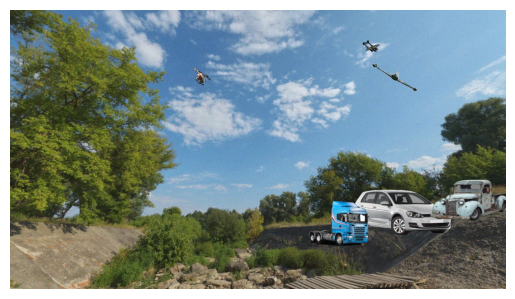

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

# pick first image
img_info = data["images"][0]

img_path = "/home/jupyter/advanced/cv/images/" + img_info["file_name"]

img = Image.open(img_path)

plt.imshow(img)
plt.axis("off")

In [6]:
image_id = img_info["id"]

anns = [a for a in data["annotations"] if a["image_id"] == image_id]

print(len(anns))
print(anns[:2])

6
[{'id': 0, 'image_id': 3235, 'category_id': 4, 'area': 2904.0011880398424, 'bbox': [1365.0, 117.0000010728836, 66.0000228881836, 44.00000274181366], 'iscrowd': 0}, {'id': 1, 'image_id': 3235, 'category_id': 4, 'area': 18403.999258041313, 'bbox': [1402.9999923706055, 205.9999930858612, 172.00000762939453, 106.999990940094], 'iscrowd': 0}]


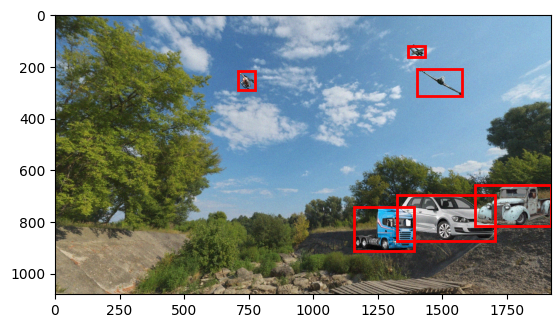

In [7]:
import matplotlib.patches as patches

fig, ax = plt.subplots(1)
ax.imshow(img)

for ann in anns:
    x, y, w, h = ann["bbox"]
    
    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        edgecolor='red',
        facecolor='none'
    )
    
    ax.add_patch(rect)

plt.show()

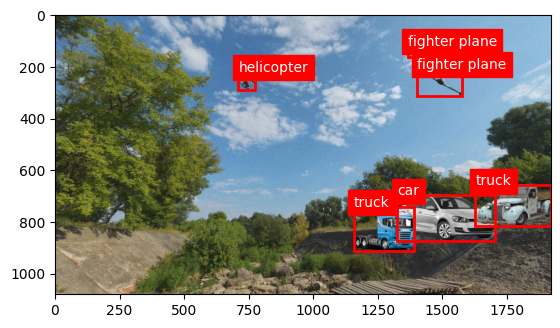

In [8]:
# map category_id to name
cat_map = {c["id"]: c["name"] for c in data["categories"]}

fig, ax = plt.subplots(1)
ax.imshow(img)

for ann in anns:
    x, y, w, h = ann["bbox"]
    label = cat_map[ann["category_id"]]
    
    rect = patches.Rectangle((x, y), w, h,
                             linewidth=2,
                             edgecolor='red',
                             facecolor='none')
    
    ax.add_patch(rect)
    ax.text(x, y, label, color='white', backgroundcolor='red')

plt.show()

In [9]:
print("Total images:", len(data["images"]))
print("Total annotations:", len(data["annotations"]))
print("Total categories:", len(data["categories"]))

Total images: 5000
Total annotations: 19392
Total categories: 18


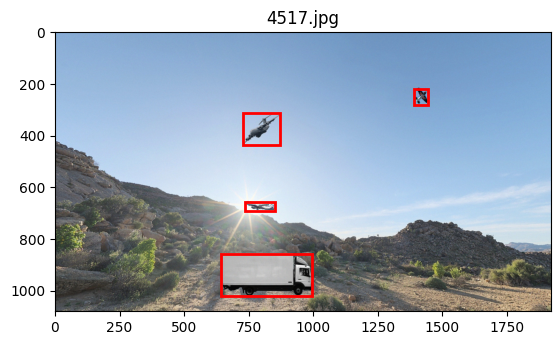

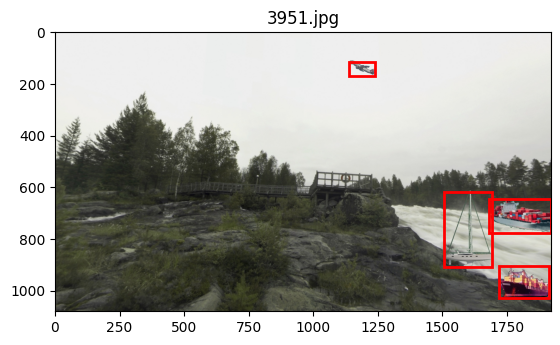

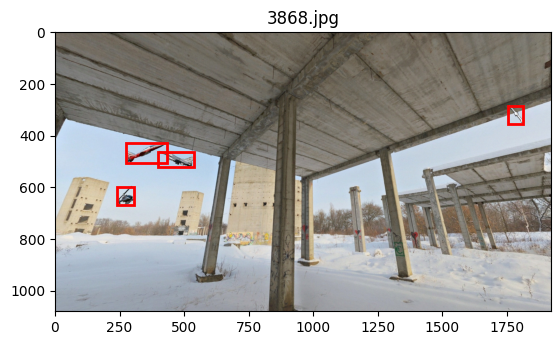

In [10]:
import random

for i in range(3):
    img_info = random.choice(data["images"])
    img_path = "/home/jupyter/advanced/cv/images/" + img_info["file_name"]
    
    img = Image.open(img_path)
    image_id = img_info["id"]
    
    anns = [a for a in data["annotations"] if a["image_id"] == image_id]

    fig, ax = plt.subplots(1)
    ax.imshow(img)

    for ann in anns:
        x, y, w, h = ann["bbox"]
        rect = patches.Rectangle((x, y), w, h,
                                 linewidth=2,
                                 edgecolor='red',
                                 facecolor='none')
        ax.add_patch(rect)

    plt.title(img_info["file_name"])
    plt.show()

In [11]:
from collections import Counter

counts = Counter([ann["category_id"] for ann in data["annotations"]])

for k, v in counts.items():
    print(k, v)

4 1207
5 1597
9 983
8 2353
10 2440
14 348
13 367
3 2515
12 717
6 910
7 805
1 1703
2 941
11 1312
0 292
15 251
16 368
17 283


In [12]:
from collections import Counter

# count again
counts = Counter([ann["category_id"] for ann in data["annotations"]])

# map id → name
cat_map = {c["id"]: c["name"] for c in data["categories"]}

for k, v in counts.items():
    print(cat_map[k], ":", v)

fighter plane : 1207
helicopter : 1597
car : 983
truck : 2353
tank : 2440
yacht : 348
cargo ship : 367
fighter jet : 2515
van : 717
light aircraft : 910
missile : 805
commercial aircraft : 1703
drone : 941
bus : 1312
cargo aircraft : 292
cruise ship : 251
warship : 368
sailboat : 283


In [13]:
len(data["images"])

5000

In [14]:
len(data["categories"])

18

In [15]:

for c in data["categories"]:
    print(c["id"], c["name"])

0 cargo aircraft
1 commercial aircraft
2 drone
3 fighter jet
4 fighter plane
5 helicopter
6 light aircraft
7 missile
8 truck
9 car
10 tank
11 bus
12 van
13 cargo ship
14 yacht
15 cruise ship
16 warship
17 sailboat


In [16]:
from collections import defaultdict
from tqdm import tqdm

# map category id → 0 to 17
cat_ids = sorted([c["id"] for c in data["categories"]])
cat_id_to_idx = {cat_id: idx for idx, cat_id in enumerate(cat_ids)}

# group annotations by image
image_to_anns = defaultdict(list)

for ann in data["annotations"]:
    image_to_anns[ann["image_id"]].append(ann)

# convert each image
for img_info in tqdm(data["images"]):
    img_id = img_info["id"]
    file_name = img_info["file_name"]
    width = img_info["width"]
    height = img_info["height"]

    anns = image_to_anns[img_id]

    label_lines = []

    for ann in anns:
        x, y, w, h = ann["bbox"]

        # convert to YOLO format
        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height
        w_norm = w / width
        h_norm = h / height

        class_id = cat_id_to_idx[ann["category_id"]]

        label_lines.append(f"{class_id} {x_center} {y_center} {w_norm} {h_norm}")

    # THIS IS THE LINE YOU ASKED ABOUT
    label_path = f"{OUTPUT_PATH}/labels/{file_name.replace('.jpg', '.txt')}"

    with open(label_path, "w") as f:
        f.write("\n".join(label_lines))

100%|██████████| 5000/5000 [00:00<00:00, 13653.76it/s]


In [17]:
# Train YOLO: 

In [22]:
import random
import shutil
from pathlib import Path

BASE_PATH = Path("/home/jupyter/advanced/cv")
OUTPUT_PATH = Path("/home/jupyter/yolo")

images_dir = BASE_PATH / "images"
labels_dir = OUTPUT_PATH / "labels"

train_img_dir = OUTPUT_PATH / "train/images"
val_img_dir = OUTPUT_PATH / "val/images"
train_lbl_dir = OUTPUT_PATH / "train/labels"
val_lbl_dir = OUTPUT_PATH / "val/labels"

for d in [train_img_dir, val_img_dir, train_lbl_dir, val_lbl_dir]:
    d.mkdir(parents=True, exist_ok=True)

images = list(images_dir.glob("*.jpg")) + list(images_dir.glob("*.png"))

print("Images found:", len(images))

random.seed(42)
random.shuffle(images)

split_idx = int(len(images) * 0.8)
train_images = images[:split_idx]
val_images = images[split_idx:]

def copy_files(image_list, img_out, lbl_out):
    for img_path in image_list:
        label_path = labels_dir / f"{img_path.stem}.txt"

        shutil.copy(img_path, img_out / img_path.name)

        if label_path.exists():
            shutil.copy(label_path, lbl_out / label_path.name)
        else:
            print("Missing label:", label_path)

copy_files(train_images, train_img_dir, train_lbl_dir)
copy_files(val_images, val_img_dir, val_lbl_dir)

print("Train:", len(train_images))
print("Val:", len(val_images))

Images found: 5000
Train: 4000
Val: 1000


In [19]:
names = [c["name"] for c in sorted(data["categories"], key=lambda x: x["id"])]

yaml_content = f"""
path: /home/jupyter/yolo
train: train/images
val: val/images

nc: {len(names)}
names: {names}
"""

with open("/home/jupyter/yolo/data.yaml", "w") as f:
    f.write(yaml_content)

print("data.yaml created")

data.yaml created


In [20]:
!pip install ultralytics

In [8]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")  # start with small model

model.train(
    data="/home/jupyter/yolo/data.yaml",
    epochs=30,
    imgsz=960,
    batch=-1,
    patience=20,
    cache=True
)

New https://pypi.org/project/ultralytics/8.4.51 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.12.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jupyter/yolo/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tra

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fdbc47f03b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    

In [9]:
# evaluate best model before adding noise

metrics = model.val()

print(metrics.box.map)
print(metrics.box.map50)

Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.12.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,132,550 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 12.3±3.0 MB/s, size: 878.7 KB)
val: Scanning /home/jupyter/yolo/val/labels.cache... 1000 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 381.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 3.1it/s 20.7s0.3ss
                   all       1000       3876      0.985      0.967      0.989      0.941
        cargo aircraft         63         63      0.989      0.921      0.972      0.937
   commercial aircraft        301        353      0.977      0.946      0.991      0.939
                 drone        171        187       0.92      0.963      0.977      0.904
           fighter jet        375        471      0.986      0.924      0.986      0.916
         fighter plane        212      

In [4]:
import cv2
import numpy as np
from skimage.metrics import structural_similarity as ssim
from pathlib import Path

In [5]:
# add adversarial noise

def add_noise(img):
    img = img.astype(np.float32)

    # Gaussian noise
    noise = np.random.normal(0, 6, img.shape)
    noisy = img + noise

    # Slight brightness/contrast shift
    noisy = noisy * 1.03 + 2

    # Clip back to valid image range
    noisy = np.clip(noisy, 0, 255).astype(np.uint8)

    return noisy

In [6]:
# check threshold
def rmse(img1, img2):
    return np.sqrt(np.mean((img1.astype(np.float32) - img2.astype(np.float32)) ** 2))

def check_threshold(original, noisy, max_rmse=10, min_ssim=0.95):
    original_gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    noisy_gray = cv2.cvtColor(noisy, cv2.COLOR_BGR2GRAY)

    rmse_score = rmse(original, noisy)
    ssim_score = ssim(original_gray, noisy_gray)

    passed = rmse_score <= max_rmse and ssim_score >= min_ssim

    return passed, rmse_score, ssim_score

In [5]:
len(list(Path("/home/jupyter/yolo/val/images").glob("*")))

1000

In [9]:
from pathlib import Path
import cv2

val_original_dir = Path("/home/jupyter/yolo/val/images")
noisy_dir = Path("/home/jupyter/yolo/val_noisy")

noisy_dir.mkdir(parents=True, exist_ok=True)

# only first 50 images for testing
image_list = list(val_original_dir.glob("*"))[:50]

for img_path in image_list:
    img = cv2.imread(str(img_path))

    if img is None:
        continue

    noisy = add_noise(img)

    cv2.imwrite(str(noisy_dir / img_path.name), noisy)

print("Done")

Done


In [10]:
print(list(Path("/home/jupyter/yolo/val_noisy").glob("*"))[:5])

[PosixPath('/home/jupyter/yolo/val_noisy/664.jpg'), PosixPath('/home/jupyter/yolo/val_noisy/2553.jpg'), PosixPath('/home/jupyter/yolo/val_noisy/3099.jpg'), PosixPath('/home/jupyter/yolo/val_noisy/3429.jpg'), PosixPath('/home/jupyter/yolo/val_noisy/4500.jpg')]


In [11]:
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

results = model.predict(
    source="/home/jupyter/yolo/val_noisy",
    conf=0.25,
    imgsz=512,
    save=False
)

print("Prediction completed")


image 1/530 /home/jupyter/yolo/val_noisy/100.jpg: 288x512 1 tank, 44.4ms
image 2/530 /home/jupyter/yolo/val_noisy/1000.jpg: 288x512 1 commercial aircraft, 1 car, 2 tanks, 1 van, 8.8ms
image 3/530 /home/jupyter/yolo/val_noisy/1009.jpg: 288x512 2 helicopters, 1 tank, 1 sailboat, 8.8ms
image 4/530 /home/jupyter/yolo/val_noisy/1012.jpg: 288x512 1 drone, 1 fighter jet, 2 tanks, 8.6ms
image 5/530 /home/jupyter/yolo/val_noisy/1016.jpg: 288x512 2 trucks, 2 warships, 8.6ms
image 6/530 /home/jupyter/yolo/val_noisy/1020.jpg: 288x512 1 drone, 1 fighter jet, 8.6ms
image 7/530 /home/jupyter/yolo/val_noisy/1045.jpg: 288x512 1 fighter jet, 1 helicopter, 3 trucks, 8.7ms
image 8/530 /home/jupyter/yolo/val_noisy/105.jpg: 288x512 (no detections), 8.6ms
image 9/530 /home/jupyter/yolo/val_noisy/1053.jpg: 288x512 1 commercial aircraft, 2 drones, 1 fighter jet, 1 car, 1 bus, 8.6ms
image 10/530 /home/jupyter/yolo/val_noisy/1066.jpg: 288x512 2 commercial aircrafts, 1 fighter jet, 2 trucks, 3 tanks, 8.7ms
image

In [13]:
from pathlib import Path
import cv2

val_original_dir = Path("/home/jupyter/yolo/val/images")
noisy_dir = Path("/home/jupyter/yolo/val_noisy")

noisy_dir.mkdir(parents=True, exist_ok=True)

# ALL images
image_list = list(val_original_dir.glob("*"))

for img_path in image_list:

    output_path = noisy_dir / img_path.name

    # skip images already generated
    if output_path.exists():
        continue

    img = cv2.imread(str(img_path))

    if img is None:
        continue

    noisy = add_noise(img)

    passed, rmse_score, ssim_score = check_threshold(img, noisy)

    if passed:
        cv2.imwrite(str(output_path), noisy)
    else:
        cv2.imwrite(str(output_path), img)

print("All noisy images generated")

All noisy images generated


In [14]:
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

results = model.predict(
    source="/home/jupyter/yolo/val_noisy",
    conf=0.25,
    imgsz=512,
    save=False
)

print("Prediction completed")


image 1/1000 /home/jupyter/yolo/val_noisy/100.jpg: 288x512 1 tank, 9.3ms
image 2/1000 /home/jupyter/yolo/val_noisy/1000.jpg: 288x512 1 commercial aircraft, 1 car, 2 tanks, 1 van, 8.6ms
image 3/1000 /home/jupyter/yolo/val_noisy/1005.jpg: 288x512 1 commercial aircraft, 1 light aircraft, 1 car, 3 tanks, 8.6ms
image 4/1000 /home/jupyter/yolo/val_noisy/1009.jpg: 288x512 2 helicopters, 1 tank, 1 sailboat, 8.7ms
image 5/1000 /home/jupyter/yolo/val_noisy/1012.jpg: 288x512 1 drone, 1 fighter jet, 2 tanks, 8.6ms
image 6/1000 /home/jupyter/yolo/val_noisy/1016.jpg: 288x512 2 trucks, 2 warships, 8.6ms
image 7/1000 /home/jupyter/yolo/val_noisy/1020.jpg: 288x512 1 drone, 1 fighter jet, 8.6ms
image 8/1000 /home/jupyter/yolo/val_noisy/1023.jpg: 288x512 3 tanks, 8.6ms
image 9/1000 /home/jupyter/yolo/val_noisy/1038.jpg: 288x512 1 fighter jet, 1 car, 1 tank, 8.6ms
image 10/1000 /home/jupyter/yolo/val_noisy/1040.jpg: 288x512 1 commercial aircraft, 1 fighter plane, 2 trucks, 1 bus, 8.6ms
image 11/1000 /hom

In [15]:
# TEST 1 : 
metrics = model.val(
    data="/home/jupyter/yolo/data.yaml",
    split="val",
    imgsz=512
)

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.12.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1676.9±1529.1 MB/s, size: 918.0 KB)
val: Scanning /home/jupyter/yolo/val/labels.cache... 1000 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 155.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 6.2it/s 10.2s0.1s
                   all       1000       3876       0.65      0.689      0.686      0.564
        cargo aircraft         63         63          1          0      0.115     0.0891
   commercial aircraft        301        353      0.441      0.743      0.592      0.454
                 drone        171        187      0.266       0.69      0.401      0.312
           fighter jet        375        471      0.381      0.699      0.498      0.363
         fighter plane        212        230      0.344      0.178      0.274      0.209
            helicopter      

In [ ]:
# CHANGE IMAGE SIZE:

In [16]:
from pathlib import Path
import shutil

benchmark_dir = Path("/home/jupyter/yolo/benchmark")
benchmark_dir.mkdir(parents=True, exist_ok=True)

all_images = list(Path("/home/jupyter/yolo/val_noisy").glob("*"))

# use 100 images for benchmark
sample_images = all_images[:100]

for img_path in sample_images:

    destination = benchmark_dir / img_path.name

    if not destination.exists():
        shutil.copy(img_path, destination)

print("Benchmark dataset ready")

Benchmark dataset ready


In [17]:
import time
from ultralytics import YOLO

configs = [
    {
        "name": "YOLOv8n_384",
        "model": "yolov8n.pt",
        "imgsz": 384
    },
    {
        "name": "YOLOv8n_416",
        "model": "yolov8n.pt",
        "imgsz": 416
    },
    {
        "name": "YOLOv8s_512",
        "model": "runs/detect/train/weights/best.pt",
        "imgsz": 512
    }
]

results_summary = []

for config in configs:

    print(f"\nTesting {config['name']}")

    model = YOLO(config["model"])

    start = time.time()

    results = model.predict(
        source="/home/jupyter/yolo/benchmark",
        imgsz=config["imgsz"],
        conf=0.25,
        save=False,
        device=0,
        half=True,
        verbose=False
    )

    end = time.time()

    total_time = end - start
    avg_time = total_time / 100

    print(f"Total Time: {total_time:.2f} sec")
    print(f"Average per image: {avg_time:.4f} sec")

    results_summary.append({
        "config": config["name"],
        "total_time": total_time,
        "avg_per_image": avg_time
    })

print("\n=== FINAL RESULTS ===")

for result in results_summary:
    print(result)


Testing YOLOv8n_384
Total Time: 4.49 sec
Average per image: 0.0449 sec

Testing YOLOv8n_416
Total Time: 3.25 sec
Average per image: 0.0325 sec

Testing YOLOv8s_512
Total Time: 3.25 sec
Average per image: 0.0325 sec

=== FINAL RESULTS ===
{'config': 'YOLOv8n_384', 'total_time': 4.487387180328369, 'avg_per_image': 0.04487387180328369}
{'config': 'YOLOv8n_416', 'total_time': 3.2546491622924805, 'avg_per_image': 0.032546491622924806}
{'config': 'YOLOv8s_512', 'total_time': 3.249723434448242, 'avg_per_image': 0.03249723434448242}


In [ ]:
# TEST (INCREASE SPEED) 

In [25]:
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

for size in [448, 640, 768, 960]:
    print(f"\nTesting imgsz={size}")

    metrics = model.val(
        data="/home/jupyter/yolo/data.yaml",
        split="val",
        imgsz=size
    )

    print("mAP50-95:", metrics.box.map)
    print("mAP50:", metrics.box.map50)


Testing imgsz=448
Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.12.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,132,550 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3548.8±770.3 MB/s, size: 1108.2 KB)
val: Scanning /home/jupyter/yolo/val/labels.cache... 1000 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 419.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 7.1it/s 8.8s0.1s
                   all       1000       3876      0.617      0.629      0.631      0.506
        cargo aircraft         63         63          1          0     0.0978      0.069
   commercial aircraft        301        353      0.437      0.691      0.546      0.404
                 drone        171        187      0.266      0.572      0.341       0.25
           fighter jet        375        471      0.341      0.652      0.403      0.277
         fighter 

In [ ]:
# TRAINING WITH NEW MODEL: "yolov8m.pt"

In [6]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="/home/jupyter/yolo/data.yaml",
    epochs=50,
    imgsz=960,
    batch=-1,
    cache=True,
    patience=20,
    device=0,
    amp=True
)

New https://pypi.org/project/ultralytics/8.4.51 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.50 🚀 Python-3.12.13 torch-2.12.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jupyter/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f86dcd845f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    

In [ ]:
# AFTER RUNNING THE EPOCHES THEN RUN THE BELOW CODE

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="/home/jupyter/yolo/data.yaml",
    epochs=50,
    imgsz=960,
    batch=-1,
    cache=True,
    patience=20,

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=10,
    translate=0.1,
    scale=0.5,

    fliplr=0.5,
    mosaic=1.0,
    mixup=0.2,

    erasing=0.3
)

In [ ]:
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

for size in [640, 768, 896, 960]:
    print(f"\nTesting imgsz={size}")

    metrics = model.val(
        data="/home/jupyter/yolo/data.yaml",
        imgsz=size,
        split="val"
    )

    print("mAP50-95:", metrics.box.map)

In [ ]:
# TRAIN SEPARATELY TO CONFIRM (640,768,869 AND 960)

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="/home/jupyter/yolo/data.yaml",
    epochs=50,
    imgsz=768,
    batch=-1,
    cache=True,
    patience=20,
    device=0,
    amp=True,
    name="yolov8m_768"
)

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="/home/jupyter/yolo/data.yaml",
    epochs=50,
    imgsz=960,
    batch=-1,
    cache=True,
    patience=20,
    device=0,
    amp=True,
    name="yolov8m_768"
)

In [ ]:
results = model.predict(
    source=path,
    imgsz=768,
    conf=0.20,
    iou=0.6,
    half=True,
    stream=True,
    verbose=False,
    device=0
)

In [2]:
import json
import os
import random
import shutil
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm

BASE_PATH = "/home/jupyter/advanced/cv"
OUTPUT_PATH = "/home/jupyter/yolo"

with open(BASE_PATH + "/annotations.json") as f:
    data = json.load(f)

print("Images:", len(data["images"]))
print("Annotations:", len(data["annotations"]))
print("Categories:", len(data["categories"]))

Images: 5000
Annotations: 19392
Categories: 18


In [4]:

os.makedirs(OUTPUT_PATH + "/images", exist_ok=True)
os.makedirs(OUTPUT_PATH + "/labels", exist_ok=True)

cat_ids = sorted([c["id"] for c in data["categories"]])
cat_id_to_idx = {cat_id: idx for idx, cat_id in enumerate(cat_ids)}
cat_map = {c["id"]: c["name"] for c in data["categories"]}

image_to_anns = defaultdict(list)
for ann in data["annotations"]:
    image_to_anns[ann["image_id"]].append(ann)

for img_info in tqdm(data["images"]):
    img_id = img_info["id"]
    file_name = img_info["file_name"]
    width = img_info["width"]
    height = img_info["height"]

    anns = image_to_anns[img_id]
    label_lines = []

    for ann in anns:
        x, y, w, h = ann["bbox"]
        # Clamp to image bounds
        x = max(0, x)
        y = max(0, y)
        w = min(w, width - x)
        h = min(h, height - y)
        if w <= 0 or h <= 0:
            continue

        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height
        w_norm = w / width
        h_norm = h / height
        class_id = cat_id_to_idx[ann["category_id"]]
        label_lines.append(f"{class_id} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}")

    label_path = f"{OUTPUT_PATH}/labels/{file_name.replace('.jpg', '.txt').replace('.png', '.txt')}"
    with open(label_path, "w") as f:
        f.write("\n".join(label_lines))

print("Labels written!")

100%|██████████| 5000/5000 [00:00<00:00, 7551.67it/s]

Labels written!


In [5]:
# === TRAIN/VAL SPLIT (90/10 — more data for training) ===
images_dir = Path(BASE_PATH) / "images"
labels_dir = Path(OUTPUT_PATH) / "labels"

train_img_dir = Path(OUTPUT_PATH) / "train/images"
val_img_dir   = Path(OUTPUT_PATH) / "val/images"
train_lbl_dir = Path(OUTPUT_PATH) / "train/labels"
val_lbl_dir   = Path(OUTPUT_PATH) / "val/labels"

for d in [train_img_dir, val_img_dir, train_lbl_dir, val_lbl_dir]:
    d.mkdir(parents=True, exist_ok=True)

images = list(images_dir.glob("*.jpg")) + list(images_dir.glob("*.png"))
print("Total images:", len(images))

random.seed(42)
random.shuffle(images)

# 90/10 split to maximise training data
split_idx = int(len(images) * 0.9)
train_images = images[:split_idx]
val_images   = images[split_idx:]

def copy_files(image_list, img_out, lbl_out):
    for img_path in image_list:
        label_path = labels_dir / f"{img_path.stem}.txt"
        shutil.copy(img_path, img_out / img_path.name)
        if label_path.exists():
            shutil.copy(label_path, lbl_out / label_path.name)
        else:
            open(lbl_out / f"{img_path.stem}.txt", "w").close()  # empty label for background images

copy_files(train_images, train_img_dir, train_lbl_dir)
copy_files(val_images, val_img_dir, val_lbl_dir)

print(f"Train: {len(train_images)} | Val: {len(val_images)}")

Total images: 5000


KeyboardInterrupt: 

In [6]:
# === CREATE data.yaml ===
names = [c["name"] for c in sorted(data["categories"], key=lambda x: x["id"])]

yaml_content = f"""path: {OUTPUT_PATH}
train: train/images
val: val/images

nc: {len(names)}
names: {names}
"""

with open(f"{OUTPUT_PATH}/data.yaml", "w") as f:
    f.write(yaml_content)

print("data.yaml created")
print(yaml_content)

data.yaml created
path: /home/jupyter/yolo
train: train/images
val: val/images

nc: 18
names: ['cargo aircraft', 'commercial aircraft', 'drone', 'fighter jet', 'fighter plane', 'helicopter', 'light aircraft', 'missile', 'truck', 'car', 'tank', 'bus', 'van', 'cargo ship', 'yacht', 'cruise ship', 'warship', 'sailboat']

